# Lesson 15: Charge Balance Across Cells
The handling of mass transport in [Lesson 14](L14-Mass-Transfer-Limitations.ipynb) considered only the chemistry near the electrode/solution interface. This lesson will consider ionic transport across the full cell, between the electrodes where electronic charge is passed.

Today's topics:
- Ionic transport in solution
- Transference number, ionic conductivity (conductance), and ionic mobility
- The effect of membranes 

**Reference:**
- Sections 2.3 and 2.4 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [1]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets
from IPython.display import display
import schemdraw
import schemdraw.elements as elm

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE      # constants and the two-panel figure size
echem.use_style()                       # course-wide graph formatting

# 1. Liquid Junction Potentials

<div class="alert alert-block alert-info">
<b>Activity:</b> Consider the electrochemical cell sketched below. Write out the electrochemical reactions that may occur. Do you expect a spontaneous reaction? 
    <br>
    $E^{0'}$(Cu$^{2+}$/Cu) = 0.34 V
    <br>
    $E^{0'}$(Zn$^{2+}$/Zn) = -0.76 V
    <br>
    $E^{0'}$(O$_2$/H$_2$O) = 1.23 V
</div>

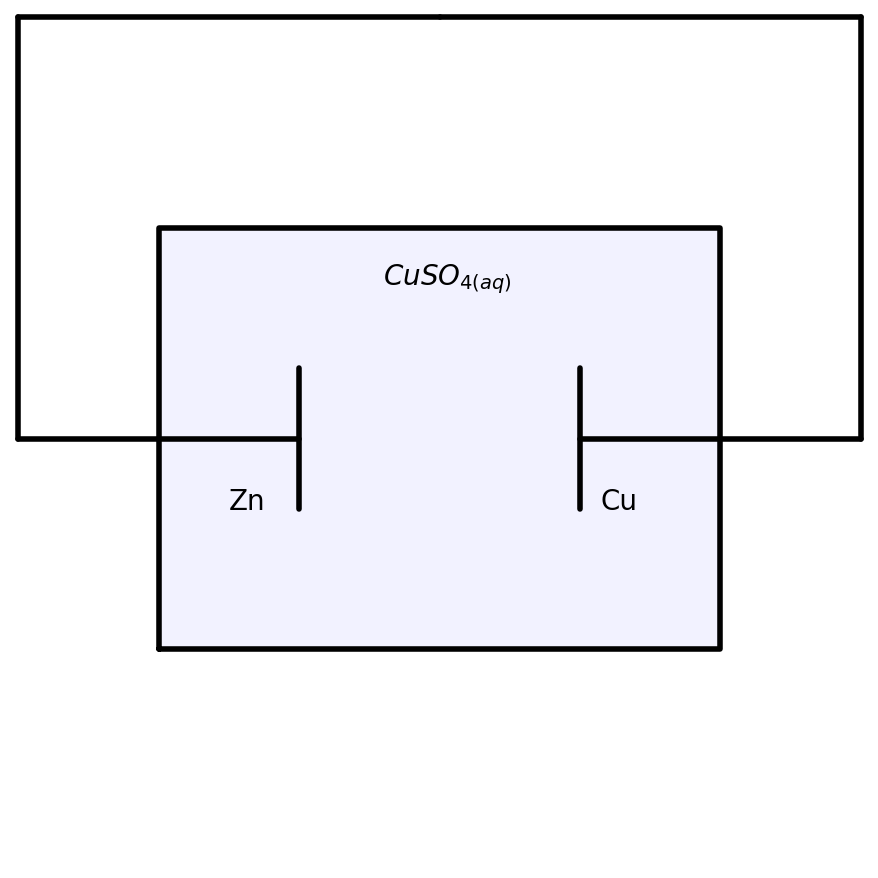

In [2]:
cell = schemdraw.Drawing(inches_per_unit=0.75)
cell.add(elm.Line().right().length(2))
cell.add(elm.Line().up())
cell.add(elm.Line().left())
cell.add(elm.Line().left())
cell.add(elm.Line().down())
cell.add(elm.Line().right().length(2))
cell.add(elm.Gap().label('').down())


# annotate diagram
fig = cell.draw()
fig.plot([0, 0],[0.5, -0.5])
fig.ax.annotate('Cu', (0.15,-0.5))
fig.plot([-2, -2],[0.5, -0.5]) # cathode
fig.ax.annotate('Zn', (-2.5,-0.5))
fig.plot([-3, 1., 1., -3, -3],[-1.5, -1.5, 1.5, 1.5, -1.5], fill=(0,0,1,0.05)) # reaction cell
fig.ax.annotate(r'$CuSO_{4 (aq)}$', (-1.4,1.1), fontsize=10)

fig.fig.savefig('../Workspace/reactioncell.png')

display(fig)

In the previous lecture we learned about how diffusion layers are formed at electrode surfaces, then subsequently expand into solution with time. We have also learned that electrochemical reactions involve the coupling of two half reactions that are separated by some physical space. How do these two diffusion layers interact? How does it affect the observed thermodynamics and kinetics in the system?

Consider the cell from above:

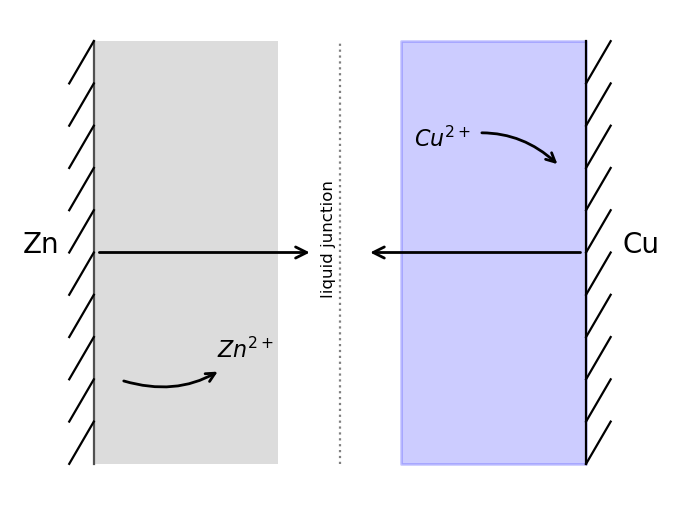

In [3]:
fig = plt.figure()
ax = plt.subplot(111)
ax.set_xlim(-0.3, 2.3)
ax.grid(visible=False)
ax.axes.set_axis_off()
ax.plot([0, 0], [0, 1], [2, 2], [0, 1], 'black')
for i in range(10):
    plt.plot([-0.1, 0],[0.1*i, 0.1+0.1*i], 'black')
    plt.plot([2., 2.1],[0.1*i, 0.1+0.1*i], 'black')

ax.annotate('Zn', (-0.29, 0.5))
ax.annotate('Cu', (2.15, 0.5))

ax.annotate(r'$Cu^{2+}$', fontsize=8,
            xy=(1.9, 0.7), xycoords='data', 
            xytext=(1.3, 0.75), textcoords='data', 
            arrowprops=dict(arrowstyle='->', color='black',
            connectionstyle="arc3,rad=-0.3")
           )

ax.annotate(r'$Zn^{2+}$', fontsize=8,
            xy=(0.1, 0.2), xycoords='data', 
            xytext=(0.5, 0.25), textcoords='data', 
            arrowprops=dict(arrowstyle='<-', color='black',
            connectionstyle="arc3,rad=-0.3")
           )

ax.annotate('',
            xy=(0, 0.5), xycoords='data', 
            xytext=(0.9, 0.5), textcoords='data', 
            arrowprops=dict(arrowstyle='<-', color='black')
           )
ax.annotate('',
            xy=(2, 0.5), xycoords='data', 
            xytext=(1.1, 0.5), textcoords='data', 
            arrowprops=dict(arrowstyle='<-', color='black')
           )


plt.fill_between([0,0.75], 0, 1, alpha=0.2)
plt.fill_between([1.25,2], 0, 1, color='blue', alpha=0.2)
plt.plot([1, 1],[0, 1], linestyle=':', c='gray')
ax.annotate('liquid junction', (0.925, 0.4), rotation=90, fontsize=6)
    
fig.savefig('../Workspace/junction.png')

There are two different diffusion gradients propagating towards each other. They will eventually meet at a liquid-liquid interface that is referred to as a **liquid junction**. Being inequivalent, the mixing of these two solutions must have thermodynamic implications. This is one example that is inherently present in every electrochemical reaction cell. There are other situations in which such junctions are introduced - for example, the use of a reference electrode often introduces a junction into the solution. 

There are three different mathematical classifications for **liquid junctions**:
1. Solutions that have the same electrolyte solution components, but at different concentrations
2. Solutions that have two different electrolytes that share a common ion; both at the same concentration
3. Solutions that satisfy neither of the above (i.e., everything more complex)


## Liquid Junctions of the First Type

Consider an electrochemical cell consisting of two platinum electrodes submerged into a reaction cell with a membrane separator between the two electrodes. One compartment has a low concentration of H$_2$SO$_4$ and the other has a higher concentration. 

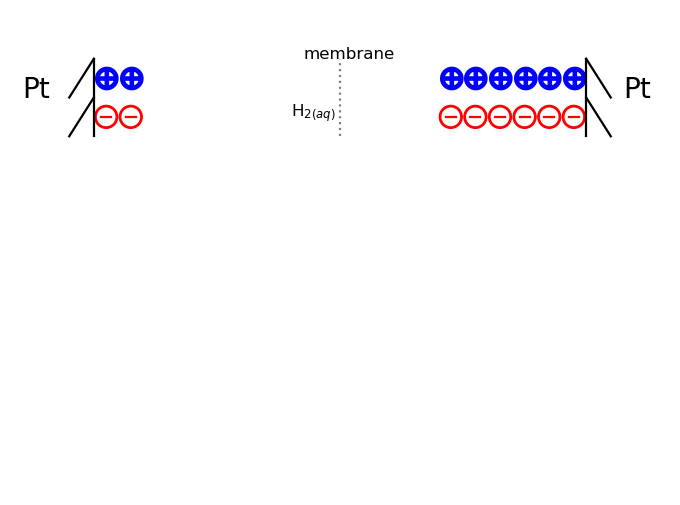

In [4]:
fig = plt.figure()
ax = plt.subplot(111)
ax.set_xlim(-0.3, 2.3)
ax.set_ylim(-0.1, 1.1)
ax.grid(visible=False)
ax.axes.set_axis_off()
ax.annotate('membrane', (0.85, 1), fontsize=6)
ax.annotate(r'H$_{2 (aq)}$', (0.8, 0.85), fontsize=6)
ax.annotate('Pt', (-0.29, 0.9))
ax.annotate('Pt', (2.15, 0.9))

# echem.draw_solution_step(ax, high, low, left_cations, right_cations,
#                              left_anions, right_anions)

# Starting point: the left compartment is dilute, the right is concentrated.
echem.draw_solution_step(ax, 1.0, 0.8, 2, 6, 2, 6)

fig.savefig('../Workspace/step0.png')

A voltage is applied to the electrode such that the platinum electrode in the more acidic compartment passes a cathodic current. Using the cartoon above, lets say that 5 electrons are passed from the left compartment into the right compartment. **What happens to the ions in the cell?**

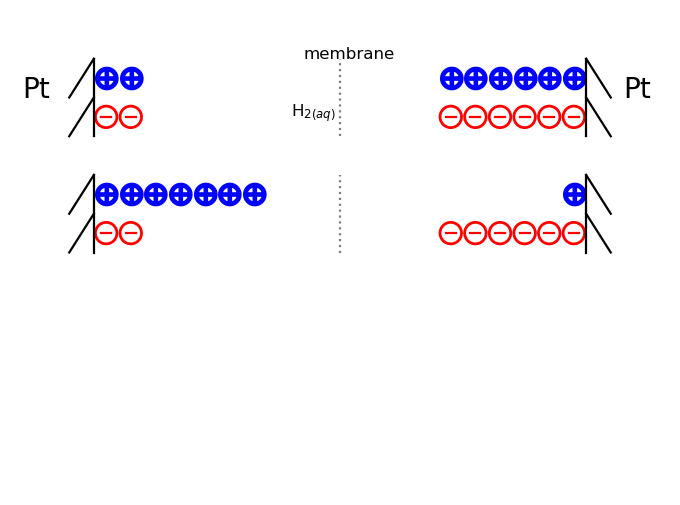

In [5]:
fig = plt.figure()
ax = plt.subplot(111)
ax.set_xlim(-0.3, 2.3)
ax.set_ylim(-0.1, 1.1)
ax.grid(visible=False)
ax.axes.set_axis_off()
ax.annotate('membrane', (0.85, 1), fontsize=6)
ax.annotate(r'H$_{2 (aq)}$', (0.8, 0.85), fontsize=6)
ax.annotate('Pt', (-0.29, 0.9))
ax.annotate('Pt', (2.15, 0.9))

# echem.draw_solution_step(ax, high, low, left_cations, right_cations,
#                              left_anions, right_anions)

# Starting point
echem.draw_solution_step(ax, 1.0, 0.8, 2, 6, 2, 6)
# HYPOTHETICAL aftermath: five electrons crossed and only the cations moved.
# This is physically unrealistic, but it makes the bookkeeping visible.
echem.draw_solution_step(ax, 0.7, 0.5, 7, 1, 2, 6)

fig.savefig('../Workspace/step1.png')

The cartoon above shows the **hypothetical** situation that is the immediate aftermath. This diagram is physically unrealistic and has not been observed experimentally, but it does prove useful for a conceptual understanding of what must happen.

This hypothetical situation is problematic...there is a massive charge imbalance in both compartments. Nature does not like charge imbalances. The ions MUST move to eliminate these imbalances. **Sketch how you think the charges will move to re-establish balance**.

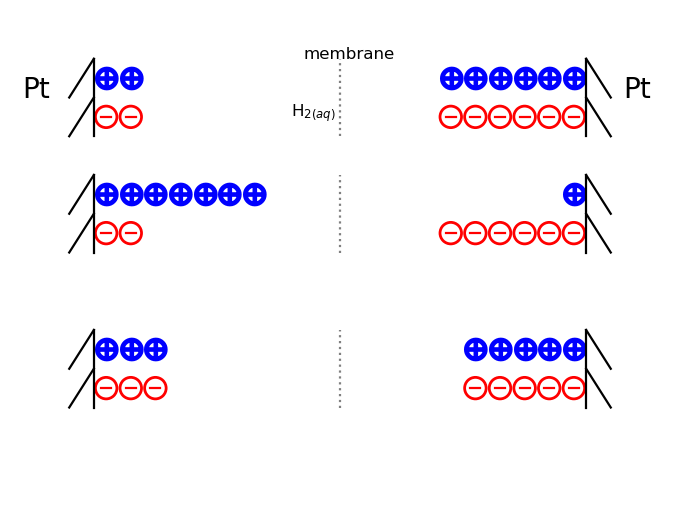

In [6]:
fig = plt.figure()
ax = plt.subplot(111)
ax.set_xlim(-0.3, 2.3)
ax.set_ylim(-0.1, 1.1)
ax.grid(visible=False)
ax.axes.set_axis_off()
ax.annotate('membrane', (0.85, 1), fontsize=6)
ax.annotate(r'H$_{2 (aq)}$', (0.8, 0.85), fontsize=6)
ax.annotate('Pt', (-0.29, 0.9))
ax.annotate('Pt', (2.15, 0.9))

# echem.draw_solution_step(ax, high, low, left_cations, right_cations,
#                              left_anions, right_anions)

# Starting point
echem.draw_solution_step(ax, 1.0, 0.8, 2, 6, 2, 6)
# The hypothetical, cations-only aftermath
echem.draw_solution_step(ax, 0.7, 0.5, 7, 1, 2, 6)
# What actually happens: BOTH ions move, and the faster one carries more charge
echem.draw_solution_step(ax, 0.3, 0.1, 3, 5, 3, 5)

fig.savefig('../Workspace/step3.png')

Surprised? There is no reason that we should expect balanced transfer of cations and anions between compartments. In reality, the fastest moving component in the system will tend to **carry the most charge**. In the situation above, this results in a net change in concentration of anions and cations in both compartments: the electrochemical reaction resulted in a change in solution composition.

This situation, where one ion carries more charge than another, is physically realistic and can be experimentally verified.

# 2. Ionic Movement in Solution

The movement of ions in solution is another form of moving charge around. We can therefore handle it by adapting the terminology used for electrical circuits. Solutions contain a characteristic **conductance** ($L$), which is the inverse of **resistance** ($R$):

$ \large L = \frac{\kappa A}{l} = \frac{1}{R} = \frac{i}{E}$

Conductance is measured in units of Siemens (S), or inverse Ohms ($\Omega^{-1}$). A single value exists for the entire solution, with the solution dimensions captured by area ($A$) and length ($l$). The **conductivity** ($\kappa$) of the solution is the ability of all ions in solution to move charges. It is measured in units of $S \cdot cm^{-1}$ and is defined as:

$ \large \kappa = F \sum_i |z_i| u_i C_i$

Where subscript $i$ values indicate individual charged components of the solution with a given charge ($z_i$) and concentration ($C_i$). Each solution only has one measured conductivity. Each individual ion has a unique **mobility** ($u_i$) that has units of $cm^2 \cdot V^{-1} \cdot s^{-1}$:

$
\large u_i = \frac{|z_i| e}{6 \pi \eta r}
$

Where $e$ is the elementary charge, $\eta$ is the viscosity of the medium, and $r$ is the radius of the ion.

In summary:
- Every ion in solution has a different **mobility**
- The ability of all ions in solution to move charge establishes one **conductivity** for the solution
- The conductivity can be represented as a **conductance**

Variations in mobility of individual ions means that each ion carries a different amount of charge across the solution: ions with higher mobility will carry a greater amount of total charge than those with low mobility. This behavior can be captured by the *dimensionless* **transference number** ($t$), which is simply the ratio of conductivity contributed by a single species to the total solution conductivity:

$ \large t_i = \frac{|z_i| u_i C_i}{\sum_j |z_j| u_j C_j}$

Based on this definition, physically realistic values lie between 0 (species $i$ carries none of the charge) and 1 (species $i$ carries all of the charge).

Due to the ability to adjust conductivity by changing solution composition and concentration, it is common practice to normalize ionic conductivity values. We note that *the positive charge and the negative charge* in solution must be equal in magnitude in the solution. A new term can be defined to describe the **concentration of positive OR negative charge** ($C_{eq}$) of a given solution:

$ C_{eq} = |z_i| C_i$

The **equivalent conductivity** of the solution ($\Lambda$) is then:

$ \large \Lambda = \frac{\kappa}{C_{eq}}$

Because the charge can be carried by both anions and cations, the total **equivalent conductivity** is the sum of **individual ionic conductivities**:

$ \large \Lambda = \lambda_+ + \lambda_-$

Following the initial definition for conductivity, each **individual ionic conductivity** can be described as:

$ \lambda_i = F u_i$

These $\lambda_i$ values are what you will find tabulated in textbooks and data repositories. These tabulated values can be used to calculate the expected ionic conductivity, or conductance, for any desired solution.

The $\lambda_i$ values can also be used to provide a shorter path to the **transference number** for a given species in solution:

$ \large t_i = \frac{\lambda_i}{\Lambda}$

Or alternatively, expanded further:

$ \large t_i = \frac{|z_i|\lambda_i C_i}{\sum_j |z_j|\lambda_jC_j}$

<div class="alert alert-block alert-info">
<b>Activity:</b> What values do you expect for the cation transference numbers in the table below? How would you measure them? Note the expected trends in the space below.
</div>

**Table: Cation transference numbers in aqueous solution at 25C.**

| Electrolyte| 0.01 M | 0.05 M| 0.10 M| 0.20 M|
| ---        | ---    | ---   | ---   | ---   |
|HCl         |        |       |       |       |
|NaCl        |        |       |       |       |
|KCl         |        |       |       |       |
|KNO$_3$     |        |       |       |       |
|K$_2$SO$_4$ |        |       |       |       |

The trends are...

- As the concentration of an individual species increases, the cation transference number: **DECREASES/REMAINS STATIC/INCREASES/OTHER**
- Moving down group 1, the cation transference number: **DECREASES/REMAINS STATIC/INCREASES/OTHER**
- Increasing the size of the anion causes the cation transference number to: **DECREASES/REMAINS STATIC/INCREASES/OTHER**

The complete table is available as **Table 2.3.1** in your Bard & Faulkner textbook.

## Calculating Liquid Junction Potentials: Symmetric Cells

The thermodynamic implications of liquid junctions can be calculated in a straightforward manner for liquid junctions of the first type. 

Consider a cell where HCl$_{aq}$ is present in both chambers, but with concentrations of 0.1 M and 1.0 M:

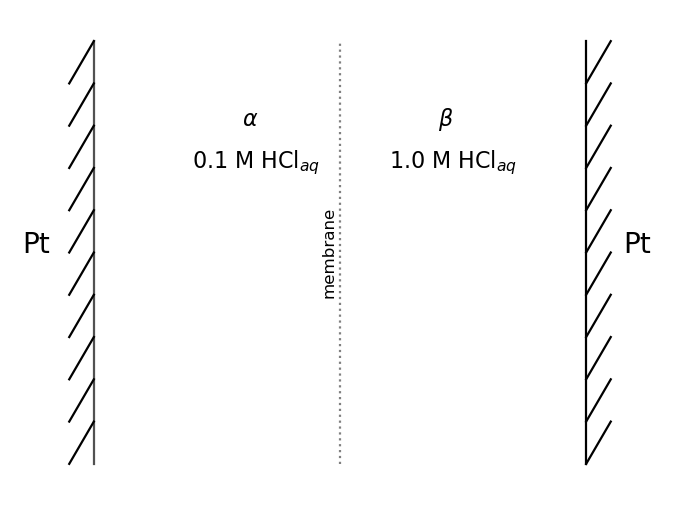

In [7]:
fig = plt.figure()
ax = plt.subplot(111)
ax.set_xlim(-0.3, 2.3)
ax.grid(visible=False)
ax.axes.set_axis_off()
ax.plot([0, 0], [0, 1], [2, 2], [0, 1], 'black')
for i in range(10):
    plt.plot([-0.1, 0],[0.1*i, 0.1+0.1*i], 'black')
    plt.plot([2., 2.1],[0.1*i, 0.1+0.1*i], 'black')

ax.annotate('Pt', (-0.29, 0.5))
ax.annotate('Pt', (2.15, 0.5))

ax.annotate(r'$\alpha$', (0.6, 0.8), fontsize=8)
ax.annotate(r'0.1 M HCl$_{aq}$', (0.4, 0.7), fontsize=8)
ax.annotate(r'$\beta$', (1.4, 0.8), fontsize=8)
ax.annotate(r'1.0 M HCl$_{aq}$', (1.2, 0.7), fontsize=8)

plt.plot([1, 1],[0, 1], linestyle=':', c='gray')
ax.annotate('membrane', (0.925, 0.4), rotation=90, fontsize=6)
    
fig.savefig('../Workspace/Ej1.png')

The situation above is an **NHE** reference electrode (right side) coupled to a similar electrode with a lower concentration of H$^+$. Being a non-equilibrium solution, there will be some potential difference between the two electrodes, $E_{cell}$. We can label the difference due to the differences in equilibrium position of redox couples at the electrode interfaces as $E_{Nernst}$. The influence due to the liquid junction can be represented as a **liquid junction potential**, ($E_j$):

$\large E_{cell} = E_{Nernst} + E_j$

The liquid junction potential can be defined as:

$\large E_j = (t_+ - t_-) \frac{RT}{F}ln\left(\frac{a^\alpha}{a^\beta}\right)$

Where the activity terms, $a^i$ are the *mean activity* for phases $\alpha$ and $\beta$:

$ a^i = a_+^i = a_-^i$

Remember, the total anionic and cationic charge within a given phase must be equivalent.

<div class="alert alert-block alert-info">
<b>Activity:</b> Calculate $E_j$ for the following cell with x = H$^+$, Na$^+$, and K$^+$.
    <br>
Pt | 0.1 M XCl | 1.0 M XCl | Pt
</div>

Note that convention for the cell written above is to consider the right hand side the 'product' and the left hand side the 'reactant'.

Run the code cell below to print the answer.

In [8]:
# Transference numbers for XCl at 0.1 M live in echem.py (Table 2.3.1 in the textbook).
# echem.junction_potential(t_cation, conc_alpha, conc_beta) applies
#     E_j = (t+ - t-) (RT/F) ln(a_alpha / a_beta)
CONC_ALPHA = 0.1        # M, left compartment
CONC_BETA = 1.0         # M, right compartment

print('X\tEj (V)')
for ion, t_cation in echem.TRANSFERENCE_NUMBERS.items():
    e_j = echem.junction_potential(t_cation, CONC_ALPHA, CONC_BETA)
    print(f'{ion}\t{e_j:.4f}')

X	Ej (V)
H+	-0.0392
Na+	0.0136
K+	0.0012


<div class="alert alert-block alert-info">
<b>Activity:</b> Using the calculated $E_j$ potentials, determine the $E_{cell}$ value that would be measured at open-circuit.
</div>

The $E^{0'}$ for both compartments is the same, so the cell potential between the two compartments is:

$ \large E_\beta - E_\alpha = -\frac{RT}{F}ln (\frac{a_{H_2}^\beta}{a^\beta{_H{^+}}}) + \frac{RT}{F}ln (\frac{a_{H_2}^\alpha}{a^\alpha{_H{^+}}}) = \frac{RT}{F}ln(\frac{a^\beta_{H^+}}{a^\alpha_{H^+}})$

A shortcut to solving this type of math comes from the realization that $R$, $T$, and $F$ are all constant. The equation can therefore be written out as:

$\large E_{cell} = 0.0591 \cdot log(\frac{a^\beta_{H^+}}{a^\alpha_{H^+}})$

The *Nernstian* shift is thus expected to be 59.1 mV per decade change in the logarithmic ratio. The sample cell has a 10-fold (1-decade) change in concentration of H$^+$, meaning there will be a 59.1 mV thermodynamic potential between the two compartments. This needs to be adjusted for the junction potential:

In [9]:
# The measured cell potential is the Nernstian difference PLUS the junction potential.
print('X\tEj (V)\tEcell (V)')
for ion, t_cation in echem.TRANSFERENCE_NUMBERS.items():
    e_j = echem.junction_potential(t_cation, CONC_ALPHA, CONC_BETA)
    e_nernst = echem.THERMAL_VOLTAGE*np.log(CONC_BETA/CONC_ALPHA)
    print(f'{ion}\t{e_j:.4f}\t{e_nernst + e_j:.4f}')

X	Ej (V)	Ecell (V)
H+	-0.0392	0.0199
Na+	0.0136	0.0727
K+	0.0012	0.0603


## Calculating Liquid Junction Potentials: Asymmetric Cells 

Asymmetric cells can arise for a number of reasons. The use of immiscible solvents, for example. 

In the second type of liquid junction there exists different electrolyte species in the two phases, but they share one common ion and the species are at the same concentration. Under these conditions, a generalized expression can be derived for the junction potential:

$ \large E_j = -\frac{RT}{F}\sum_i \int_\alpha^\beta \frac{t_i}{z_i} d\,ln(a_i)$

Expansion of this equation yields the *Henderson Equation* (see Bard & Faulkner, Page 72). In the condition that:

$ \large C^\alpha_{eq} = C^\beta_{eq}$

The Henderson equation is simplified to:

$ 
\large E_j = \pm \frac{RT}{F}ln\left(\frac{\Lambda_\beta}{\Lambda_\alpha}\right)
$

The equation is:
- Positive if a cation is shared between $\alpha$ and $\beta$
- Negative if an anion is shared between $\alpha$ and $\beta$

# 3. Membrane Potentials

Liquid junction potential are a thermodynamic feature of any system that may, or may not, have an impact on measured results. They should therefore be considered in experiment design. The same underlying concept can be harnessed for productive purposes. The **membrane potential** ($E_m$) is an example of this.

Membranes can be designed to selectively permit only ions of a single type:
- **Proton exchange membranes** allow only cations, typically H$^+$, to pass. These are well established and have been critical to *fuel cell* technology development
- **Anion exchange membranes** allow only anions to pass. These are emerging and have potential to drive commercialization of *electrolyzer* technologies

Consider the junction potentials of the first type from above. This equation can be adapted to describe the thermodynamic potential due to an ion exchange membrane. It should be obvious that such a membrane introduces a special condition. For proton exchange membranes:

$\large t_+ = 1.0$ 

and 

$\large t_- = 0$

Therefore:

$\large E_j = \frac{RT}{F}ln\left(\frac{a^\alpha}{a^\beta}\right)$

Selectively permeable membranes are a massive area of modern research, with much excitement surrounding anion exchange membranes and *bipolar membranes*. **How might one design ion exchange membranes?**

# 4. Minimizing Junction Potentials

While junction potentials can be helpful, they are often a nuisance. Strategies to minimise them can be useful for ensuring quality results. Two primary strategies exist:

#### Judicious selection of electrolyte species.

The table below shows that many ions are reasonably well behaved, but some have a tendency to carry too much or too little charge. Think critically when designing your electrolyte solution for experiments. Conductivities and mobility exist - use them! 

Take note that conductivity values reported are generally extrapolated to zero-concentration charge ($\lambda_{0,i}$). You therefore need to apply a correction (Kohlrausch's law), or calculate the transference numbers as:

$
\large t_i = \frac{|z_i|\lambda_i C_i}{\sum_j |z_j| \lambda_j C_j}
$

|Ion| $\lambda_0$ (cm$^2 \Omega^{-1}$ equiv$^{-1}$)| $u$ (cm$^2 s^{-1}$ V$^{-1}$) |
|---|---|---|
|H$^+$| 349.82| 3.625 x 10$^{-3}$|
|Na$^+$| 50.11| 5.193 x 10$^{-4}$|
|K$^+$|73.52| 7.619 x 10$^{-4}$|
|Li$^+$|38.69| 4.010 x 10$^{-4}$|
|OH$^-$| 198| 2.05 x 10$^{-3}$|
|Cl$^-$|76.34| 7.912 x 10$^{-4}$|
|NO$_3^-$|71.44| 7.404 x 10$^{-4}$|
|ClO$_4^-$| 68.0|7.05 x 10$^{-4}$|
|1/2SO$_4^{2-}$|79.8| 8.27 x 10$^{-4}$|

#### Use of a salt bridge.

Inserting a concentrated solution of an electrolyte whose cation and anion have nearly equal mobility, K$^+$ and Cl$^-$ being the classic pair, makes $t_+ \approx t_-$ and drives $E_j$ towards zero. See Section 2.3.5 in Bard & Faulkner.

<div class="alert alert-block alert-info">
<b>Activity:</b> Using the mobility table above, explain in one sentence each why KCl works as a salt bridge and why an HCl bridge would be a poor choice. A question on the next problem set will build on your answer.
</div>

# 5. Ion Selective Electrodes, as Assigned Reading

Junction potentials are usually a nuisance to be minimised, but the same physics can be put to work. This application is yours to read rather than ours to derive in class, because the mathematics is exactly what we have just done:

- **Ion selective electrodes.** The common pH meter is two reference electrodes separated by a thin glass membrane. The measured potential is $E = \mathrm{constant} + \frac{RT}{F}\ln(a^\beta_{H^+})$, which is the membrane potential above with one ion made selective. See Section 2.4 in Bard & Faulkner.

---
# Literature Examples

Ion exchange membranes are critical components in both fuel cells and modern electrolysers. These materials enable the devices to work at current densities of up to 1 A cm$^{-2}$ (WOW!) without serious resistance losses. They accomplish this by enabling 'zero-gap' configurations, where the anode and cathode can be placed within several microns of one another.

<img src='../Resources/images/fuelcell.png' width=30%>

Bipolar membranes are being actively pursued as a means to circumvent catalyst stability problems (catalysts for anodic reactions tend to be unstable in acid; catalysts for cathodic reactions tend to be unstable in alkaline solutions).

[ChemSusChem 2014, 7, 3017](https://chemistry-europe.onlinelibrary.wiley.com/doi/abs/10.1002/cssc.201402535)

<img src='../Resources/images/bpm.png' width=30%>